# Predicting Medical Insurance Costs with Machine Learning
**Domain:** Healthcare  **Dataset:** Medical Cost Personal Dataset (`insurance.csv`, public on Kaggle)  **Tools:** Python, pandas, matplotlib, seaborn, scikit-learn

## Problem statement
A health insurance company has to decide how much to charge each customer. If it charges too little for a high-risk person, it loses money. If it charges too much for a low-risk person, the customer leaves for a competitor.

We use the three types of machine learning to help:

| # | Business question | ML type | Output |
|---|---|---|---|
| 1 | How much will this person's medical charges be? | **Regression** | A number in $ |
| 2 | Is this person a high-cost customer, yes or no? | **Classification** | A category (1 / 0) |
| 3 | What kinds of customers do we have? | **Clustering** | Groups of similar customers |

## Steps
1. Load and clean → 2. Explore (EDA) → 3. Regression → 4. Classification → 5. Clustering → 6. Losses without ML and benefits with ML → 7. Conclusion

---
# Phase 1: Load and clean the data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = "/content/drive/MyDrive/Mohit_Singh_Batch147/ML Assignmenrt/insurance.csv"

df = pd.read_csv(file_path)
print("Shape (rows, columns):", df.shape)
print(df.head())

Shape (rows, columns): (1338, 7)
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520


**What each column means**

| Column | Meaning |
|---|---|
| age | Age of the person (18–64) |
| sex | male / female |
| bmi | Body Mass Index (weight compared to height). 30 or more = obese |
| children | Number of children covered by the insurance |
| smoker | yes / no |
| region | Area of the USA: northeast, northwest, southeast, southwest |
| charges | Medical costs billed by the insurance (in $). **This is what we want to predict.** |

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df.info()

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSummary of number columns:")
print(df.describe().round(2))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB

Missing values per column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate rows: 1

Summary of number columns:
           age      bmi  children   charges
count  1338.00  1338.00   1338.00   1338.00
mean     39.21    30.66      1.09  13270.42
std      14.05     6.10      1.21  12110.01
min      18.00    15.96      0.00   1121.87
25%      27.00    26.30      0.00   4740.29
50%      39.00    30.40      1

In [ ]:
# Remove the one duplicate row
df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (1337, 7)


**Data health check:** 1,338 rows, 7 columns, **no missing values**, 1 duplicate (removed). Three columns are text (sex, smoker, region) and will need **encoding** before modelling.

Charges go from about **/$1,100 to $63,800**. The average ($13,279) is much higher than the middle value ($9,386), which tells us a smaller group of people has very high charges.

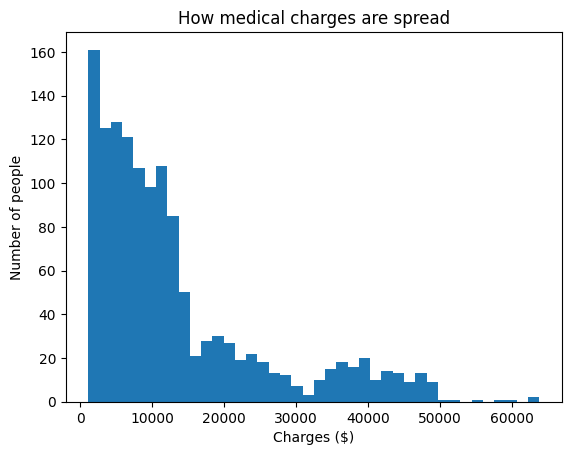

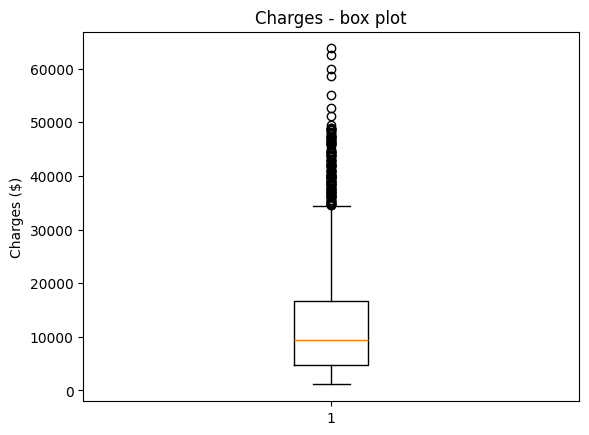

Upper fence: 34524.78
People above the fence: 139


In [ ]:
# Look at how charges are spread, and check for outliers with a box plot
plt.hist(df["charges"], bins=40)
plt.title("How medical charges are spread")
plt.xlabel("Charges ($)")
plt.ylabel("Number of people")
plt.show()

plt.boxplot(df["charges"])
plt.title("Charges - box plot")
plt.ylabel("Charges ($)")
plt.show()

Q1 = df["charges"].quantile(0.25)
Q3 = df["charges"].quantile(0.75)
IQR = Q3 - Q1
upper = Q3 + 1.5 * IQR
print("Upper fence:", round(upper, 2))
print("People above the fence:", (df["charges"] > upper).sum())

About 139 people are above the upper fence. **We keep them.** They are real, expensive customers (mostly smokers, as we'll see) and they are exactly the people the insurer needs to predict correctly.

---
# Phase 2: Exploratory Data Analysis (EDA)
What drives medical charges?

Average charges by smoker:
smoker
no      8440.66
yes    32050.23
Name: charges, dtype: float64

Number of smokers:
smoker
no     1063
yes     274
Name: count, dtype: int64


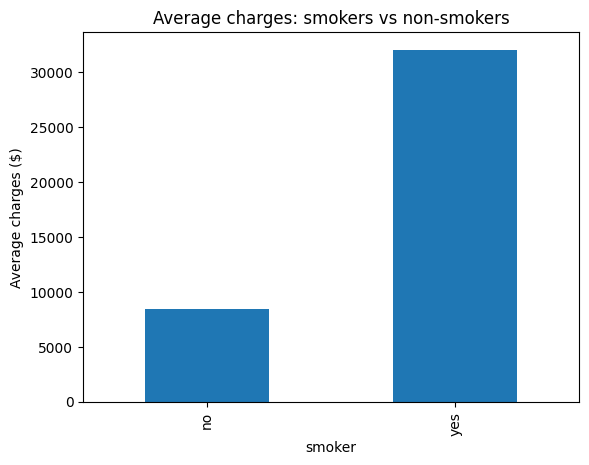

In [ ]:
# Average charges for smokers vs non-smokers
print("Average charges by smoker:")
print(df.groupby("smoker")["charges"].mean().round(2))

print("\nNumber of smokers:")
print(df["smoker"].value_counts())

df.groupby("smoker")["charges"].mean().plot(kind="bar")
plt.title("Average charges: smokers vs non-smokers")
plt.ylabel("Average charges ($)")
plt.show()

**Smokers pay almost 4 times more** on average: about $32,000 vs $8,400. Only about 20% of people smoke, but they drive a large part of the cost.

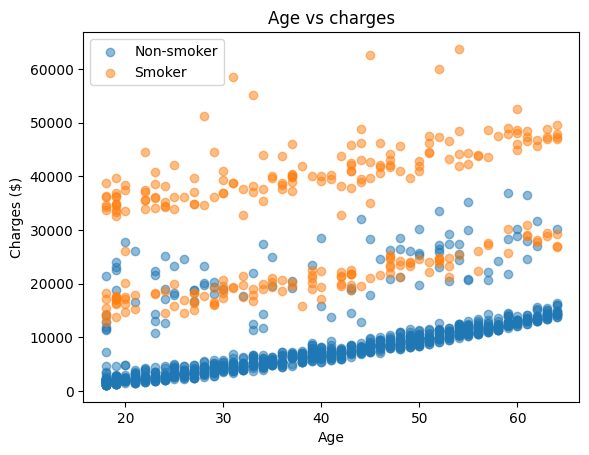

In [ ]:
# Age vs charges, coloured by smoker
smokers = df[df["smoker"] == "yes"]
non_smokers = df[df["smoker"] == "no"]

plt.scatter(non_smokers["age"], non_smokers["charges"], label="Non-smoker", alpha=0.5)
plt.scatter(smokers["age"], smokers["charges"], label="Smoker", alpha=0.5)
plt.title("Age vs charges")
plt.xlabel("Age")
plt.ylabel("Charges ($)")
plt.legend()
plt.show()

Charges **go up steadily with age** for everyone. Smokers sit on a much higher band at every age.

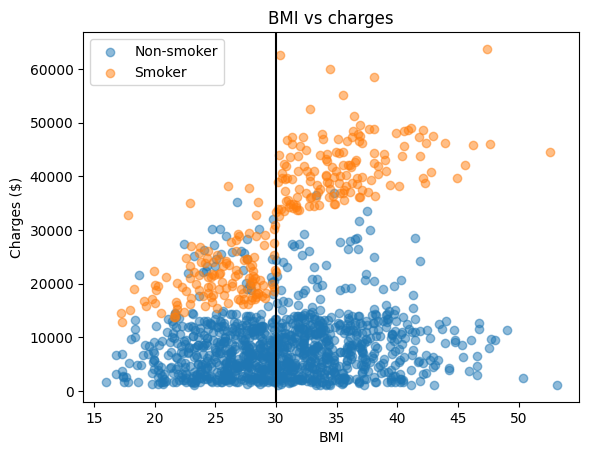

smoker  obese    
no      Not obese     7977.03
        Obese         8855.53
yes     Not obese    21363.22
        Obese        41557.99
Name: charges, dtype: float64


In [ ]:
# BMI vs charges, coloured by smoker
plt.scatter(non_smokers["bmi"], non_smokers["charges"], label="Non-smoker", alpha=0.5)
plt.scatter(smokers["bmi"], smokers["charges"], label="Smoker", alpha=0.5)
plt.axvline(30, color="black")     # BMI 30 = obesity line
plt.title("BMI vs charges")
plt.xlabel("BMI")
plt.ylabel("Charges ($)")
plt.legend()
plt.show()

# Smoker + obese combination
df["obese"] = np.where(df["bmi"] >= 30, "Obese", "Not obese")
print(df.groupby(["smoker", "obese"])["charges"].mean().round(2))

**Smoking + obesity together is the most expensive combination.** Obese smokers average about **$41,600**, about 5 times a non-obese non-smoker (~$8,000). For non-smokers, obesity alone adds very little. This is an **interaction**: two factors together matter more than each one alone.

In [ ]:
# Region, sex and children
print("By region:")
print(df.groupby("region")["charges"].mean().round(2))
print("\nBy sex:")
print(df.groupby("sex")["charges"].mean().round(2))
print("\nBy number of children:")
print(df.groupby("children")["charges"].mean().round(2))

By region:
region
northeast    13406.38
northwest    12450.84
southeast    14735.41
southwest    12346.94
Name: charges, dtype: float64

By sex:
sex
female    12569.58
male      13975.00
Name: charges, dtype: float64

By number of children:
children
0    12384.70
1    12731.17
2    15073.56
3    15355.32
4    13850.66
5     8786.04
Name: charges, dtype: float64


Region, sex and number of children make **only small differences** compared with smoking, age and BMI.

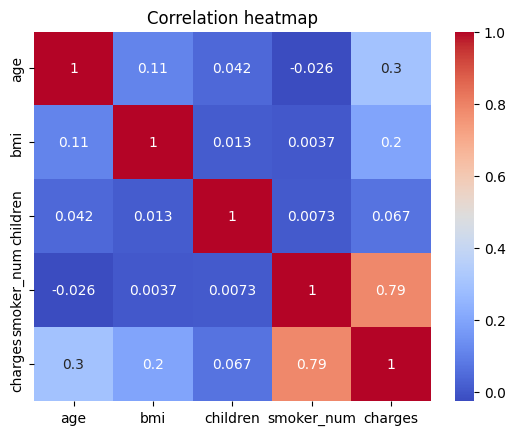

In [ ]:
# Correlation heatmap (smoker turned into 1/0 so we can include it)
df["smoker_num"] = (df["smoker"] == "yes") * 1

numbers = df[["age", "bmi", "children", "smoker_num", "charges"]]
sns.heatmap(numbers.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation heatmap")
plt.show()

**EDA summary:** smoker (correlation ~0.79 with charges) is by far the strongest factor, then age (~0.30) and BMI (~0.20). Sex, region and children matter little.

---
# Phase 3: Regression – predict the charges ($)

**Linear Regression** finds a straight-line formula: `charges = a×age + b×bmi + c×smoker + ... + constant`.
**Random Forest** builds many decision trees (each asking yes/no questions like "smoker?" or "BMI > 30?") and averages them. It can capture combinations such as "smoker AND obese".

**Scores:** **MAE** = average error in $ (lower is better). **R²** = share of the variation in charges the model explains (1 = perfect, closer to 1 is better).

In [ ]:
# ---- Step 3.1: X and y ----
X = df[["age", "sex", "bmi", "children", "smoker", "region"]]
y = df["charges"]

# ---- Step 3.2: Encoding (turn text into 0/1 columns) ----
# drop_first=True: for smoker we only need ONE column (smoker_yes): 1 = yes, 0 = no
X = pd.get_dummies(X, drop_first=True, dtype=int)
print("Columns after encoding:", X.columns.tolist())
print(X.head())

Columns after encoding: ['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']
   age     bmi  children  sex_male  smoker_yes  region_northwest  \
0   19  27.900         0         0           1                 0   
1   18  33.770         1         1           0                 0   
2   28  33.000         3         1           0                 0   
3   33  22.705         0         1           0                 1   
4   32  28.880         0         1           0                 1   

   region_southeast  region_southwest  
0                 0                 1  
1                 1                 0  
2                 1                 0  
3                 0                 0  
4                 0                 0  


In [ ]:
# ---- Step 3.3: Train / test split (70 / 30) ----
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
print("Train rows:", X_train.shape[0], " Test rows:", X_test.shape[0])

Train rows: 935  Test rows: 402


In [ ]:
# ---- Step 3.4: Linear Regression ----
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

lin = LinearRegression()
lin.fit(X_train, y_train)

train_pred = lin.predict(X_train)
test_pred = lin.predict(X_test)

print("LINEAR REGRESSION")
print("Train -> MAE: $", round(mean_absolute_error(y_train, train_pred), 2), " R2:", round(r2_score(y_train, train_pred), 3))
print("Test  -> MAE: $", round(mean_absolute_error(y_test, test_pred), 2), " R2:", round(r2_score(y_test, test_pred), 3))

# What the formula learned: how much each column adds to the charges
print("\nEffect of each column on charges ($):")
print(pd.Series(lin.coef_, index=X.columns).round(2))

LINEAR REGRESSION
Train -> MAE: $ 4165.83  R2: 0.736
Test  -> MAE: $ 4181.82  R2: 0.772

Effect of each column on charges ($):
age                   251.25
bmi                   328.38
children              522.16
sex_male             -111.91
smoker_yes          22874.45
region_northwest     -465.75
region_southeast     -936.10
region_southwest     -765.58
dtype: float64


**Reading the formula:** being a smoker adds about **$22,900** to the charges. Every extra year of age adds about **$250**, and every extra BMI point about **$330**. This is the big advantage of Linear Regression: it's easy to explain.

Test R² ≈ 0.77: good, but it misses the smoker + obesity combination because a straight line can't capture interactions.

In [ ]:
# ---- Step 3.5: Random Forest (no limit) ----
from sklearn.ensemble import RandomForestRegressor

rf_full = RandomForestRegressor(n_estimators=100, random_state=42)
rf_full.fit(X_train, y_train)

print("RANDOM FOREST (no depth limit)")
print("Train R2:", round(r2_score(y_train, rf_full.predict(X_train)), 3))
print("Test  R2:", round(r2_score(y_test, rf_full.predict(X_test)), 3))

RANDOM FOREST (no depth limit)
Train R2: 0.974
Test  R2: 0.864


Train R² 0.97 but test R² 0.86: a big gap. That's **overfitting**: the trees grew deep enough to memorise the training customers. We fix it by limiting how deep each tree can grow.

In [ ]:
# ---- Step 3.6: Random Forest with max_depth = 5 (controls overfitting) ----
rf = RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)
rf.fit(X_train, y_train)

train_pred = rf.predict(X_train)
test_pred = rf.predict(X_test)

print("RANDOM FOREST (max_depth=5)")
print("Train -> MAE: $", round(mean_absolute_error(y_train, train_pred), 2), " R2:", round(r2_score(y_train, train_pred), 3))
print("Test  -> MAE: $", round(mean_absolute_error(y_test, test_pred), 2), " R2:", round(r2_score(y_test, test_pred), 3))

# Baseline: what if we simply guessed the average charges for everyone?
average_guess = np.full(len(y_test), y_train.mean())
print("\nBaseline (guess the average) -> Test MAE: $", round(mean_absolute_error(y_test, average_guess), 2))

RANDOM FOREST (max_depth=5)
Train -> MAE: $ 2140.56  R2: 0.886
Test  -> MAE: $ 2559.25  R2: 0.873

Baseline (guess the average) -> Test MAE: $ 9423.66


Limiting the depth made the model slightly worse on training data but **better on new data**. This is the bias–variance trade-off from class: we look for the point where test error is lowest.

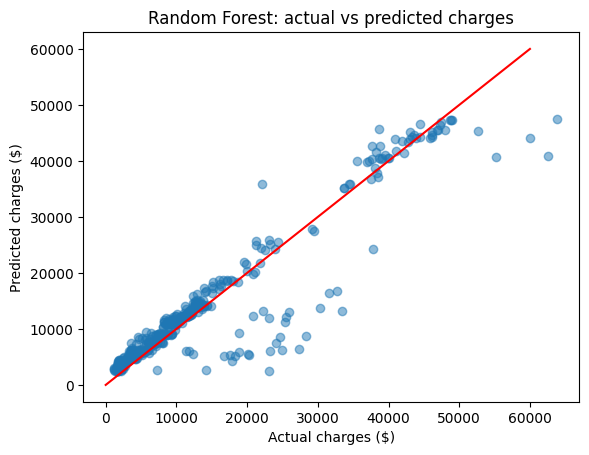

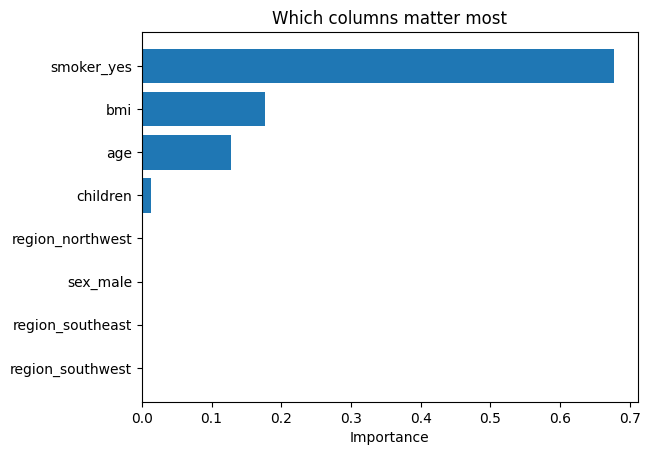

In [ ]:
# ---- Step 3.7: Actual vs predicted + feature importance ----
plt.scatter(y_test, test_pred, alpha=0.5)
plt.plot([0, 60000], [0, 60000], color="red")    # perfect prediction line
plt.title("Random Forest: actual vs predicted charges")
plt.xlabel("Actual charges ($)")
plt.ylabel("Predicted charges ($)")
plt.show()

importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
plt.barh(importance.index, importance.values)
plt.title("Which columns matter most")
plt.xlabel("Importance")
plt.show()

In [ ]:
# ---- Step 3.8: Predict charges for new customers ----
new_people = pd.DataFrame({
    "age":              [25, 25, 55, 55],
    "bmi":              [24, 24, 34, 34],
    "children":         [0, 0, 2, 2],
    "sex_male":         [1, 1, 0, 0],
    "smoker_yes":       [0, 1, 0, 1],
    "region_northwest": [0, 0, 0, 0],
    "region_southeast": [1, 1, 1, 1],
    "region_southwest": [0, 0, 0, 0],
})

new_people["predicted_charges"] = rf.predict(new_people[X.columns]).round(2)
print(new_people[["age", "bmi", "smoker_yes", "predicted_charges"]])

   age  bmi  smoker_yes  predicted_charges
0   25   24           0            4262.03
1   25   24           1           17850.59
2   55   34           0           13357.57
3   55   34           1           44258.34


The same 25-year-old is predicted to cost several times more if he smokes, and a 55-year-old obese smoker comes out as the most expensive. The model gives the insurer a fair, data-based price for each new customer.

---
# Phase 4: Classification – is this a high-cost customer?

We create a yes/no target: **High_Cost = 1** if charges are in the **top 25%** (above about $16,660), otherwise 0.

**Logistic Regression** gives the probability of being high-cost (0 to 1); above 0.5 → "yes".
**Decision Tree** asks yes/no questions in a flowchart. It's easy to show to a manager.

**Scores:** **Accuracy** = % correct overall. **Precision** = when it says "high-cost", how often it's right. **Recall** = of all real high-cost people, how many it caught. **F1** = balance of the two. **AUC** = how well it ranks high-cost people above others (1 = perfect, 0.5 = guessing).

In [ ]:
# ---- Step 4.1: Create the target ----
limit = df["charges"].quantile(0.75)
df["High_Cost"] = (df["charges"] > limit) * 1

print("High-cost limit: $", round(limit, 2))
print(df["High_Cost"].value_counts())
print("Share of high-cost customers:", round(df["High_Cost"].mean() * 100, 1), "%")

High-cost limit: $ 16657.72
High_Cost
0    1003
1     334
Name: count, dtype: int64
Share of high-cost customers: 25.0 %


Only 25% are high-cost, so the classes are **imbalanced**. We handle this two ways (from the 13 Sep notes):
- `stratify` keeps the same 75/25 mix in train and test.
- `class_weight="balanced"` makes mistakes on the smaller class count more, so the model doesn't ignore it.

**Important:** we do NOT use `charges` as an input. High_Cost is made from charges, so that would be giving the model the answer (**data leakage**).

In [ ]:
# ---- Step 4.2: Split (same X as before - it does not contain charges) ----
y_class = df["High_Cost"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y_class, test_size=0.3, random_state=42, stratify=y_class)

In [ ]:
# ---- Step 4.3: Logistic Regression ----
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score

log_model = LogisticRegression(max_iter=1000, class_weight="balanced")
log_model.fit(X_train, y_train)
log_pred = log_model.predict(X_test)

print("LOGISTIC REGRESSION")
print("Train accuracy:", round(accuracy_score(y_train, log_model.predict(X_train)), 3))
print("Test accuracy :", round(accuracy_score(y_test, log_pred), 3))
print("AUC           :", round(roc_auc_score(y_test, log_model.predict_proba(X_test)[:, 1]), 3))
print(confusion_matrix(y_test, log_pred))
print(classification_report(y_test, log_pred, digits=3))

LOGISTIC REGRESSION
Train accuracy: 0.924
Test accuracy : 0.928
AUC           : 0.883
[[297   5]
 [ 24  76]]
              precision    recall  f1-score   support

           0      0.925     0.983     0.953       302
           1      0.938     0.760     0.840       100

    accuracy                          0.928       402
   macro avg      0.932     0.872     0.897       402
weighted avg      0.928     0.928     0.925       402



In [ ]:
# ---- Step 4.4: Decision Tree ----
from sklearn.tree import DecisionTreeClassifier, plot_tree

tree = DecisionTreeClassifier(max_depth=3, class_weight="balanced", random_state=42)
tree.fit(X_train, y_train)
tree_pred = tree.predict(X_test)

print("DECISION TREE")
print("Train accuracy:", round(accuracy_score(y_train, tree.predict(X_train)), 3))
print("Test accuracy :", round(accuracy_score(y_test, tree_pred), 3))
print("AUC           :", round(roc_auc_score(y_test, tree.predict_proba(X_test)[:, 1]), 3))
print(confusion_matrix(y_test, tree_pred))
print(classification_report(y_test, tree_pred, digits=3))

DECISION TREE
Train accuracy: 0.934
Test accuracy : 0.933
AUC           : 0.883
[[299   3]
 [ 24  76]]
              precision    recall  f1-score   support

           0      0.926     0.990     0.957       302
           1      0.962     0.760     0.849       100

    accuracy                          0.933       402
   macro avg      0.944     0.875     0.903       402
weighted avg      0.935     0.933     0.930       402



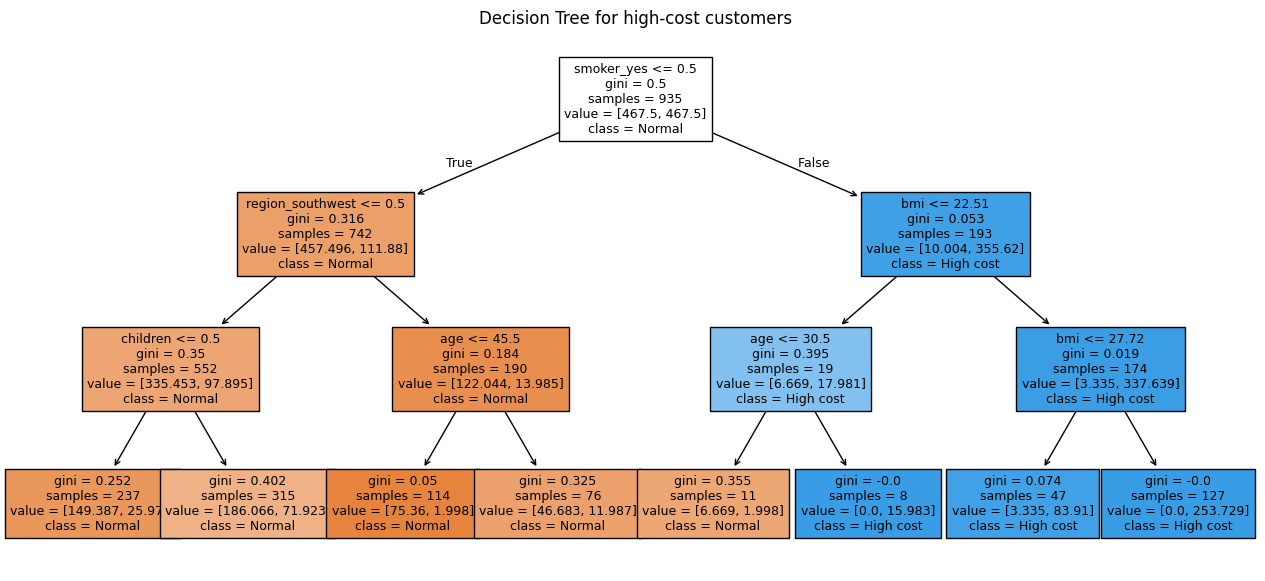

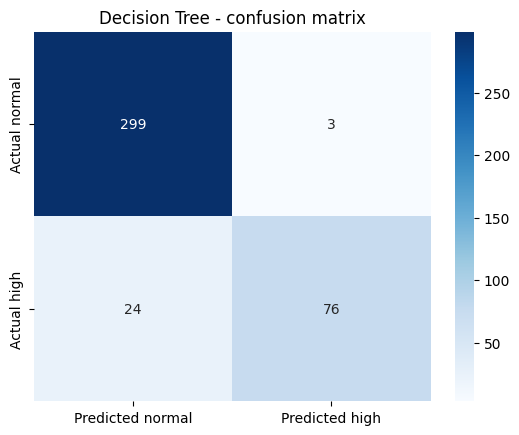

In [ ]:
# ---- Step 4.5: Draw the tree and the confusion matrix ----
plt.figure(figsize=(16, 7))
plot_tree(tree, feature_names=list(X.columns), class_names=["Normal", "High cost"],
          filled=True, fontsize=9)
plt.title("Decision Tree for high-cost customers")
plt.show()

sns.heatmap(confusion_matrix(y_test, tree_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted normal", "Predicted high"],
            yticklabels=["Actual normal", "Actual high"])
plt.title("Decision Tree - confusion matrix")
plt.show()

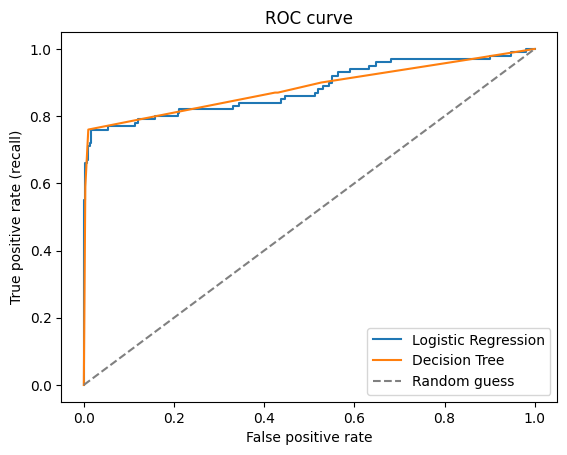

In [ ]:
# ---- Step 4.6: ROC curve (both models) ----
from sklearn.metrics import roc_curve

fpr1, tpr1, _ = roc_curve(y_test, log_model.predict_proba(X_test)[:, 1])
fpr2, tpr2, _ = roc_curve(y_test, tree.predict_proba(X_test)[:, 1])

plt.plot(fpr1, tpr1, label="Logistic Regression")
plt.plot(fpr2, tpr2, label="Decision Tree")
plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random guess")
plt.title("ROC curve")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate (recall)")
plt.legend()
plt.show()

**Results (test data):**

| Model | Accuracy | Precision (high-cost) | Recall (high-cost) | F1 | AUC |
|---|---|---|---|---|---|
| Logistic Regression | ~0.93 | ~0.94 | ~0.76 | ~0.84 | ~0.88 |
| **Decision Tree (depth 3)** | **~0.93** | **~0.96** | ~0.76 | **~0.85** | ~0.88 |

Both are close. We choose the **Decision Tree** because it's slightly better and **anyone can read it**: the first question is "Is the person a smoker?", then BMI and age. Train and test accuracy are almost the same, so **no overfitting**.

**What it misses:** about 24 of 100 high-cost people. These are mostly **older non-smokers** with high bills (illness that the data can't see, since there's no medical history column). That's an honest limitation.

---
# Phase 5: Clustering – what kinds of customers do we have?

No target here. **KMeans** puts customers into K groups of similar people:
1. Pick K centre points. 2. Each customer joins the nearest centre. 3. Move each centre to the middle of its group. 4. Repeat until stable.

KMeans measures **distance**, and charges (thousands) would drown out BMI (tens). So we **scale** first with StandardScaler (from the 5 Sep notes).

In [ ]:
# ---- Step 5.1: Choose the columns and scale them ----
from sklearn.preprocessing import StandardScaler

cluster_data = df[["age", "bmi", "smoker_num", "charges"]]

scaler = StandardScaler()
cluster_scaled = scaler.fit_transform(cluster_data)
print(pd.DataFrame(cluster_scaled, columns=cluster_data.columns).head().round(2))

    age   bmi  smoker_num  charges
0 -1.44 -0.45        1.97     0.30
1 -1.51  0.51       -0.51    -0.95
2 -0.80  0.38       -0.51    -0.73
3 -0.44 -1.31       -0.51     0.72
4 -0.51 -0.29       -0.51    -0.78


K = 2  inertia: 3181.5  silhouette: 0.485
K = 3  inertia: 2257.6  silhouette: 0.367
K = 4  inertia: 1862.1  silhouette: 0.348
K = 5  inertia: 1477.9  silhouette: 0.359
K = 6  inertia: 1220.0  silhouette: 0.346
K = 7  inertia: 1089.0  silhouette: 0.343
K = 8  inertia: 981.1  silhouette: 0.333


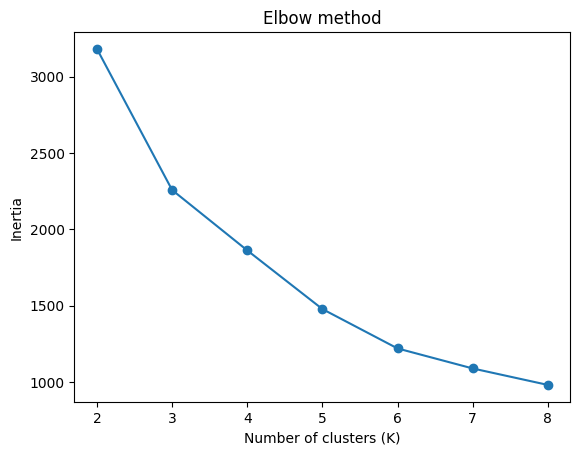

In [ ]:
# ---- Step 5.2: Elbow method + silhouette score ----
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_list = [2, 3, 4, 5, 6, 7, 8]
inertia_list = []

for k in k_list:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(cluster_scaled)
    inertia_list.append(km.inertia_)
    print("K =", k, " inertia:", round(km.inertia_, 1), " silhouette:", round(silhouette_score(cluster_scaled, km.labels_), 3))

plt.plot(k_list, inertia_list, marker="o")
plt.title("Elbow method")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.show()

K = 2 has the highest silhouette, but it just splits smokers from non-smokers, which we already know. The elbow bends at **K = 3**, which also has the next-best silhouette. **We choose K = 3.**

In [ ]:
# ---- Step 5.3: KMeans with K = 3 ----
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Cluster"] = kmeans.fit_predict(cluster_scaled)

summary = df.groupby("Cluster")[["age", "bmi", "smoker_num", "charges"]].mean()
summary["People"] = df.groupby("Cluster").size()
print(summary.round(2))

# Name each cluster from its averages
names = {}
for number, row in summary.iterrows():
    if row["smoker_num"] > 0.5:
        names[number] = "High risk: smokers"
    elif row["age"] > 40:
        names[number] = "Medium risk: older non-smokers"
    else:
        names[number] = "Low risk: young non-smokers"

df["Group"] = df["Cluster"].map(names)
print()
print(df["Group"].value_counts())

           age    bmi  smoker_num   charges  People
Cluster                                            
0        27.62  29.37         0.0   5088.74     545
1        51.81  32.00         0.0  11967.30     518
2        38.51  30.71         1.0  32050.23     274

Group
Low risk: young non-smokers       545
Medium risk: older non-smokers    518
High risk: smokers                274
Name: count, dtype: int64


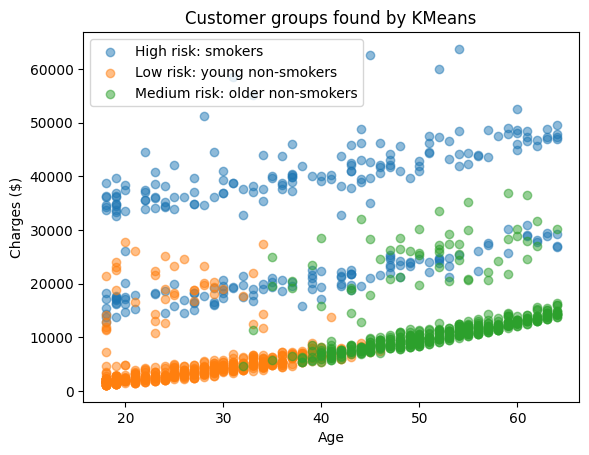

In [ ]:
# ---- Step 5.4: Plot the groups ----
for group in df["Group"].unique():
    part = df[df["Group"] == group]
    plt.scatter(part["age"], part["charges"], label=group, alpha=0.5)

plt.title("Customer groups found by KMeans")
plt.xlabel("Age")
plt.ylabel("Charges ($)")
plt.legend()
plt.show()

---
# Phase 6: Losses without ML, and benefits with ML

In [ ]:
# ---- Step 6.1: What smoking costs in our own data ----
smoker_avg = df[df["smoker"] == "yes"]["charges"].mean()
non_smoker_avg = df[df["smoker"] == "no"]["charges"].mean()
smoker_count = (df["smoker"] == "yes").sum()

extra_cost = (smoker_avg - non_smoker_avg) * smoker_count
print("Average extra cost per smoker: $", round(smoker_avg - non_smoker_avg, 2))
print("Total extra cost from smokers in this data: $", round(extra_cost, 2))
print("Smokers' share of all charges:", round(df[df["smoker"] == "yes"]["charges"].sum() / df["charges"].sum() * 100, 1), "%")

# If the insurer charged everyone the same average price
flat_price = df["charges"].mean()
under_charged = df[df["charges"] > flat_price]["charges"].sum() - flat_price * (df["charges"] > flat_price).sum()
print("\nWith one flat price for everyone ($", round(flat_price, 2), "),")
print("money lost on customers who cost more than they paid: $", round(under_charged, 2))

Average extra cost per smoker: $ 23609.57
Total extra cost from smokers in this data: $ 6469022.6
Smokers' share of all charges: 49.5 %

With one flat price for everyone ($ 13279.12 ),
money lost on customers who cost more than they paid: $ 6078310.01


### Losses without ML
- **In our data:** smokers are ~20% of customers but cause about **half of all charges**, roughly $23,600 extra per smoker. An insurer that prices everyone the same loses money on high-risk customers and overcharges low-risk ones, who then leave. With one flat price for everyone, the insurer would under-charge its expensive customers by about **$6 million** in this small dataset alone.
- **Smoking:** smoking-related illness cost the US **more than $600 billion in 2018**, including **more than $240 billion in healthcare spending**. ([Tobacco Control Factsheet 2025](https://chronicdisease.org/wp-content/uploads/2025/05/Tobacco-Control-Factsheet-2025.pdf))
- **Obesity:** a CDC and RTI study estimated obesity costs up to **$147 billion a year** in medical spending, with obese people spending **$1,429 (42%) more** on medical care than people of normal weight. ([Healthcare Finance News, 2009](https://www.healthcarefinancenews.com/news/cdc-annual-medical-costs-obesity-may-be-high-147b))

### Benefits with ML
- **Fairer, more accurate pricing:** our Random Forest predicts each person's charges with an average error of about $2,560, versus about $9,400 if we simply guessed the average for everyone (see Step 3.6).
- **Early risk flags:** the classifier picks out high-cost customers with ~93% accuracy, so the insurer can offer prevention programmes before costs grow.
- **Targeted programmes:** clustering shows where to spend: quit-smoking help for the high-risk group gives the biggest saving.
- **Industry evidence:** insurers that have scaled AI beyond pilot projects report **3–5 percentage-point better loss ratios**. On a $1 billion book, a 4-point gain is about **$40 million** of extra underwriting profit a year. ([Actuary.info, 2026](https://actuary.info/insights/scaled-ai-adopters-loss-ratio-3-5-point-edge))

---
# Phase 7: Conclusion

**Findings**
1. **Smoking is the biggest cost driver:** smokers cost almost 4× more (~$32,000 vs ~$8,400).
2. **Age and BMI** come next; **smoking + obesity** together is the most expensive combination (~$41,600).
3. Sex, region and number of children have little effect.

**Models**
| Task | Best model | Result |
|---|---|---|
| Regression | Random Forest (max_depth=5) | Test R² ≈ 0.87, MAE ≈ $2,560 |
| Classification | Decision Tree (depth 3) | Accuracy ≈ 93%, precision ≈ 96%, AUC ≈ 0.88 |
| Clustering | KMeans, K = 3 | Low-risk young, medium-risk older, high-risk smokers |
